# A4.1: COVID-19 em raio-X de tórax: GAN condicional e recall com e sem sintético

**Requisitos.** GPU recomendada (Colab T4 ou Apple MPS). Memória medida no treino completo: 1,5 GB de RAM no processo; a GPU usa bem menos que os 16 GB da T4 (lotes de 64 imagens 64 x 64 na GAN e de 32 imagens 224 x 224 na ResNet-18).
Dados: o dataset do Kaggle `sachinkumar413/covid-pneumonia-normal-chest-xray-images` (cerca de 1 GB), baixado por `make data`.

**Tempo estimado.** Só mostrar os resultados (padrão, `RODAR_TREINO = False`): menos de 1 minuto.
Treinar tudo (`RODAR_TREINO = True`): cerca de 35 minutos (medido: 31 min num Apple M5 com a GPU dividida com outros treinos; 2 GANs de 150 épocas, cerca de 11 min cada, e 6 treinos da ResNet-18, cerca de 9 min no total).
O tempo medido de cada etapa sai do `manifest.json` e é impresso abaixo.

Este notebook é vitrine: ele importa o pacote `visaocomp` e chama as mesmas classes do `make run-a4`.
Nenhum número é digitado; tudo vem de `outputs/<run_id>/`.

In [1]:
# No Colab: monte o Drive, clone o repositório e instale o pacote (descomente).
# from google.colab import drive; drive.mount('/content/drive')
# !git clone https://github.com/lararli/ml-visao-computacional.git && cd ml-visao-computacional && pip install -e . && make data
import os
import subprocess
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from visaocomp.a4.config import load_a4_config
from visaocomp.a4.report import find_complete_run
from visaocomp.paths import repo_root

ROOT = repo_root()
cfg = load_a4_config()
RODAR_TREINO = False  # True: treina tudo de novo (cerca de 35 minutos)

In [2]:
if RODAR_TREINO:
    subprocess.run(["python", "scripts/run_a4.py", "--force"], cwd=ROOT, check=True)
run = find_complete_run(ROOT / "outputs", cfg.sha256)
assert run is not None, "nenhuma execução completa: rode `make run-a4` ou RODAR_TREINO = True"
manifest = pd.read_json(run / "manifest.json", typ="series")
print("execução:", run.name, "| commit:", manifest["git"]["commit"][:7], "| dispositivo:", manifest["device"])
print("tempo por etapa (s):", manifest["durations_s"])

execução: 20261012-222622-a4 | commit: 1570d30 | dispositivo: mps
tempo por etapa (s): {'caso': 0.2, 'gan_sem_mitigacao': 630.3, 'gan_com_mitigacao': 662.0, 'sintetico': 0.4, 'classificador': 541.6, 'total': 1858.9}


## 1. O caso remontado: cópias removidas e teste real separado primeiro

In [3]:
dedup = pd.read_json(run / "dedup.json", typ="series")
display(dedup[["n_in", "copias_removidas", "removidas_por_conflito_de_rotulo", "n_out", "max_distance"]].to_frame("valor"))
display(pd.DataFrame(manifest["counts"]["caso"]).T)

,valor
n_in,5228
copias_removidas,1092
removidas_por_conflito_de_rotulo,6
n_out,4130
max_distance,2


,NORMAL,PNEUMONIA,COVID
train,672,192,96
val,168,48,24
test,150,150,150


## 2. GAN condicional: sem e com mitigação

,sem_mitigacao,com_mitigacao
estratégias,nenhuma,"label smoothing (0.9), spectral norm no discri..."
passos D,2250,2250
passos G,2250,2250
FID final,545.9,344.3
melhor FID,490.1,318.9
época do melhor,30,100
diversidade COVID,0.16,0.11
D dominou,True,False
colapso de modo,True,True


variante usada para o sintético: com_mitigacao


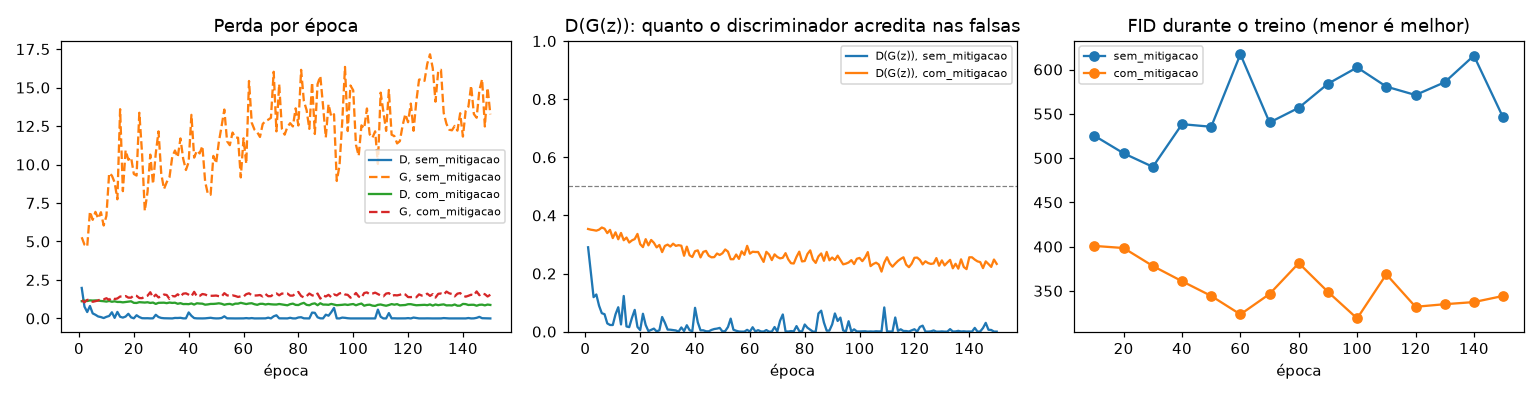

In [4]:
import json
gan = json.loads((run / "gan_metrics.json").read_text())
rows = {}
for name, r in gan["runs"].items():
    rows[name] = {
        "estratégias": ", ".join(r["strategies"]) or "nenhuma",
        "passos D": r["n_d_steps"], "passos G": r["n_g_steps"],
        "FID final": round(r["fid_final"], 1), "melhor FID": round(r["fid_best"], 1),
        "época do melhor": r["fid_best_epoch"],
        "diversidade COVID": round(r["diagnostico"]["diversidade_covid"], 2),
        "D dominou": r["diagnostico"]["discriminador_dominou"],
        "colapso de modo": r["diagnostico"]["colapso_de_modo"],
    }
display(pd.DataFrame(rows))
print("variante usada para o sintético:", gan["chosen_for_synthetic"])
display(Image(filename=str(run / "gan_comparison.png")))

**sem_mitigacao**, última época (uma linha por classe: NORMAL, PNEUMONIA, COVID)

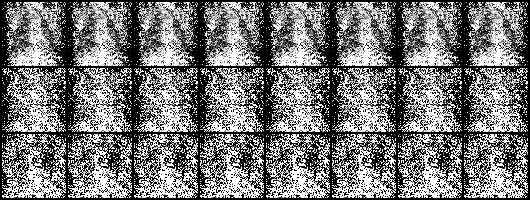

**com_mitigacao**, última época (uma linha por classe: NORMAL, PNEUMONIA, COVID)

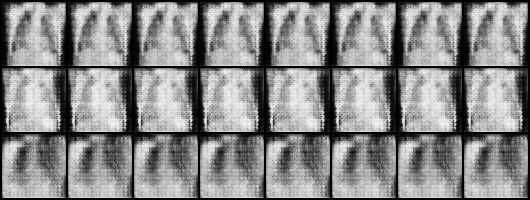

**COVID sintéticas que entram no treino**

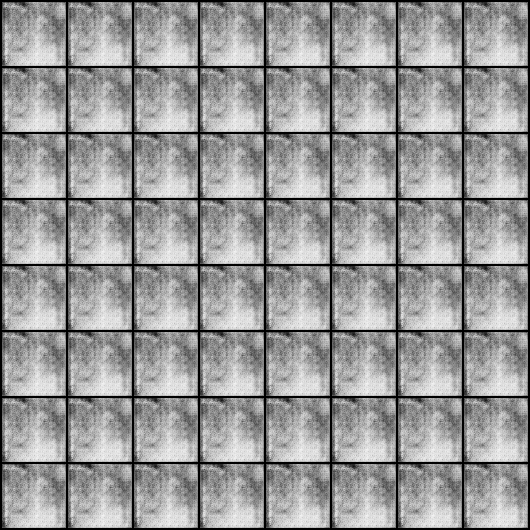

In [5]:
for name, r in gan["runs"].items():
    display(Markdown(f"**{name}**, última época (uma linha por classe: NORMAL, PNEUMONIA, COVID)"))
    display(Image(filename=str(run / "gan" / name / r["sample_grids"][-1])))
display(Markdown("**COVID sintéticas que entram no treino**"))
display(Image(filename=str(run / "synthetic_grid.png")))

## 3. Recall da COVID no teste real, com e sem sintético (3 seeds)

,condition,seed,recall_covid,balanced_accuracy,ppv_covid_prevalencia_caso,best_epoch,n_train,n_synthetic
0,sem_sintetico,0,0.966667,0.968889,1.000000,8,960,0
1,sem_sintetico,1,0.973333,0.962222,1.000000,9,960,0
2,sem_sintetico,2,0.960000,0.946667,1.000000,6,960,0
3,com_sintetico,0,0.966667,0.962222,1.000000,11,1560,600
4,com_sintetico,1,0.953333,0.957778,1.000000,12,1560,600
5,com_sintetico,2,0.973333,0.960000,0.986486,8,1560,600


,n,mean,std,min,max,ci_low,ci_high
sem_sintetico,3.0,0.967,0.007,0.960,0.973,0.950,0.983
com_sintetico,3.0,0.964,0.010,0.953,0.973,0.939,0.990


diferença pareada (com - sem): -0.002, IC 95% [-0.044, 0.039] -> inconclusivo


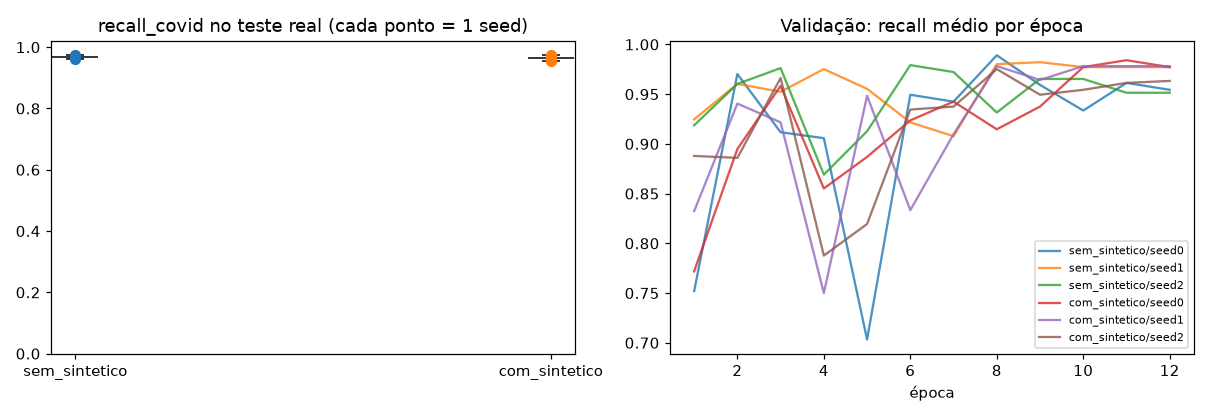

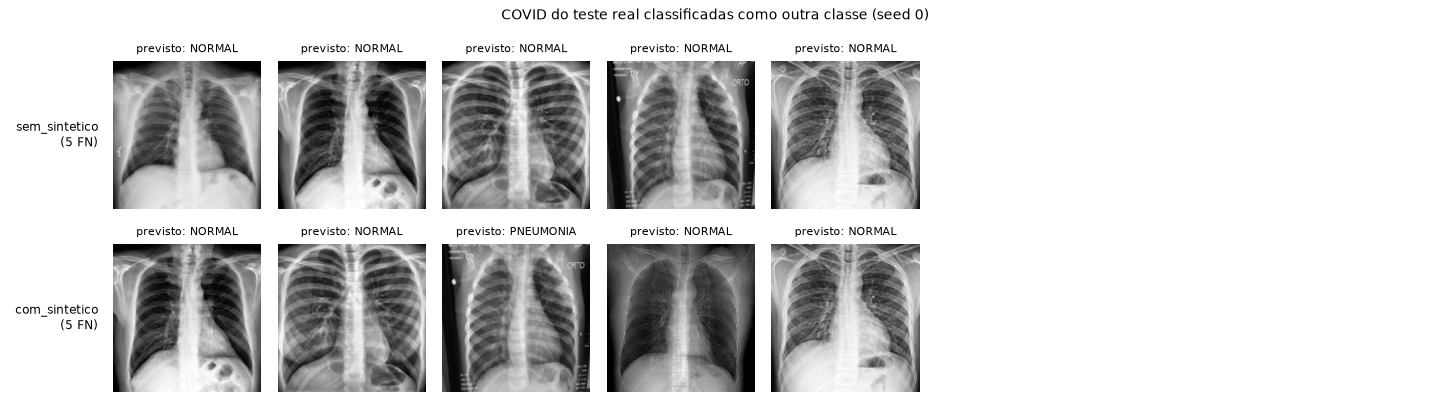

In [6]:
rec = pd.read_csv(run / "recall" / "recall.csv")
display(rec[["condition", "seed", "recall_covid", "balanced_accuracy", "ppv_covid_prevalencia_caso", "best_epoch", "n_train", "n_synthetic"]])
summary = json.loads((run / "recall" / "recall_summary.json").read_text())
table = {c: {k: round(v, 3) for k, v in s["recall_covid"].items()} for c, s in summary["conditions"].items()}
display(pd.DataFrame(table).T)
d = summary["paired_difference"]
print(f"diferença pareada (com - sem): {d['mean']:.3f}, IC 95% [{d['ci_low']:.3f}, {d['ci_high']:.3f}] -> {d['verdict']}")
display(Image(filename=str(run / "recall" / "recall.png")))
display(Image(filename=str(run / "recall" / "falsos_negativos.png")))

## 4. Diagnóstico e plano

Os problemas do projeto anterior (com o impacto clínico de cada um) e o plano de melhoria estão em
`reports/sections/a4.md`, gerado pelo mesmo `make run-a4` a partir destes resultados.

In [7]:
text = (ROOT / "reports" / "sections" / "a4.md").read_text()
start = text.index("## Plano de melhoria integrado")
display(Markdown(text[start:]))

## Plano de melhoria integrado

Cada problema da lista acima tem uma ação. O plano se organiza em dados, modelo, métrica, augmentation sintética e critério de adoção clínica.

| Problema | Ação |
|---|---|
| 1. Accuracy como única métrica | recall da COVID como métrica principal, matriz de confusão e recall por classe |
| 2. Desbalanceamento | class weights (já aplicado aqui) e sintético condicionado |
| 3. Split sem estratificação e sem teste | teste real separado primeiro; estratificação; o teste é usado uma vez |
| 4. Sem pré-treino, overfitting | ResNet-18 pré-treinada, fine-tuning, weight decay |
| 5. Sem augmentation | augmentation leve e plausível para raio-X |
| 6. Otimização sem critério | AdamW com agenda, escolha da época na validação, várias seeds |
| 7. Cópias e vazamento | dedup por pHash antes do split; split por paciente quando houver o identificador |
| 8. Resultado sem intervalo nem limiar | média e IC em seeds; limiar escolhido para sensibilidade |

### Dados e validação

Dedup por hash perceptual antes de qualquer split (aqui removeu 21,0% das imagens). Teste real separado primeiro e nunca usado para escolher nada. Quando houver identificador de paciente, separar por paciente. Validação externa com imagens de outro hospital antes de qualquer uso.

### Modelo

Partir de pesos pré-treinados (ImageNet, ou melhor, um modelo pré-treinado em raio-X de tórax) e fazer fine-tuning com AdamW, agenda de learning rate, weight decay e escolha da época pela validação, como aqui. Class weights na perda. Repetir em várias seeds e reportar média e intervalo. Como próximo passo, comparar com uma arquitetura maior (DenseNet-121, comum em raio-X) com o mesmo protocolo, e calibrar as probabilidades (temperature scaling) para que o limiar signifique algo.

### Métrica

Recall (sensibilidade) da COVID como métrica principal, porque o custo clínico é o falso negativo. Junto: recall por classe, matriz de confusão, recall médio das três classes e precisão da COVID na prevalência esperada no hospital (não na do teste). Todo número com intervalo. Escolher o limiar de decisão na validação para atingir a sensibilidade alvo, e reportar a especificidade que sobra.

### Augmentation sintética

GAN condicional treinada só com o treino, com mitigação de instabilidade (label smoothing, spectral norm, replay buffer) e escolha do checkpoint pelo FID (aqui o melhor FID foi 318,9). Três travas antes de usar: (1) FID e diversidade medidos e sem colapso de modo; (2) o teste fica 100% real; (3) o ganho no recall da COVID precisa ter intervalo acima de zero em várias seeds. Neste experimento a trava (1) falhou: a GAN escolhida colapsou (diversidade 0,11), então as COVID sintéticas são quase a mesma imagem repetida (veredito do recall: inconclusivo). O sintético não entra no pipeline até uma GAN passar pelas três travas. Próximos passos: atacar o colapso com minibatch discrimination (o discriminador compara as imagens do lote entre si) e learning rates diferentes para D e G; gerar em resolução maior (128 ou 256 px) para não ensinar ao classificador que "imagem borrada = COVID", revisar uma amostra das geradas com um radiologista e testar um modelo de difusão com o mesmo protocolo.

### Critério de adoção clínica

O modelo só vai para uso assistido (segunda leitura, nunca decisão sozinho) se, num teste externo real com a prevalência do hospital: (1) o recall da COVID for pelo menos 0,90 com o limite inferior do IC 95% acima de 0,85; (2) nenhuma classe tiver recall abaixo de 0,80; (3) a precisão da COVID na prevalência real for informada à equipe; (4) o resultado se mantiver num período silencioso (o modelo roda sem influenciar a conduta, comparado com o laudo). Depois, monitorar o recall por mês e retreinar quando cair. Hoje o recall médio da COVID no teste real é 0,967 sem sintético e 0,964 com sintético; o critério (1) é atingido no teste interno, o que ainda não dispensa o teste externo.

## Limites

- Uma execução de cada GAN (uma seed): a comparação sem e com mitigação não tem intervalo.
- O sintético é 64 x 64 redimensionado para 224: o classificador pode associar imagem borrada a COVID. O teste real mede o efeito final, mas não separa as causas.
- 3 seeds dão um intervalo largo; o teste tem 150 COVID, então cada imagem vale 0,0067 de recall.
- O dataset junta fontes diferentes por classe; o modelo pode aprender a fonte, não a doença. Só um teste externo responde isso.
